# train2 — 가벼운 NumPy CNN, 10 epoch
눈 이미지와 head pose로 시선의 yaw, pitch를 예측합니다.

- **NumPy만으로 학습**: ReLU, He 초기화, Adam, Dropout을 직접 구현합니다.
- **속도 개선**: 첫 합성곱을 두 칸씩 이동하고, 채널·연결층 크기를 줄여 연산량을 줄입니다. 입력은 그대로 `(1,36,60)`입니다.
- **과적합 확인**: 별도 진단 모델에서 학습·검증 곡선을 확인합니다.
- **최종 평가**: 매번 새 모델을 14명으로 10 epoch 학습하고, 남은 1명을 테스트하는 15-fold LOPO입니다.
- OpenCV는 이미지 읽기, pandas·matplotlib은 표·그래프에만 사용합니다.

**NumPy 자체는 GPU를 지원하지 않습니다.** Apple Silicon에서는 NumPy의 Apple Accelerate 기반 행렬 연산을 사용합니다.
이는 GPU 학습이 아닙니다. 현재 환경에서 실제 속도를 재는 셀도 제공합니다.
[NumPy 장치 지원](https://numpy.org/doc/stable/user/basics.interoperability.html) ·
[macOS Accelerate 지원](https://numpy.org/doc/2.0/release/2.0.0-notes.html)

커널을 재시작하고 위에서 아래로 실행하세요. 기존 `train.ipynb`와 결과는 그대로 보존합니다.


## 1. 실행 환경을 확인하는 셀
NumPy 버전, CPU 종류, 행렬 연산 라이브러리를 보여줍니다.
설치가 필요하면 첫 줄의 `#`을 지우고 실행한 뒤 커널을 재시작하세요.


In [1]:
# %pip install "numpy>=2.0" opencv-python pandas matplotlib

import os
# NumPy를 처음 불러오기 전에 설정합니다. 이미 불러왔다면 커널 재시작 후 적용됩니다.
# 작은 행렬 연산에서 지나치게 많은 CPU 스레드를 사용하는 일을 줄입니다.
for key in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS",
            "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(key, "4")

import ast
import platform
import contextlib
import io
import json
import hashlib
import time
import sys
from pathlib import Path

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi":110, "axes.grid":True, "grid.alpha":0.25})

print("Python:", sys.executable)
print("NumPy:", np.__version__, "| 실행 구조:", platform.machine())
try:
    BLAS_CONFIG = json.dumps(np.show_config(mode="dicts"), default=str)
except TypeError:  # 오래된 NumPy에서도 환경 확인이 가능하도록 합니다.
    with contextlib.redirect_stdout(io.StringIO()) as build_output:
        np.show_config()
    BLAS_CONFIG = build_output.getvalue()
print("행렬 연산:", "Apple Accelerate" if "accelerate" in BLAS_CONFIG.lower()
      else "아래 설정에서 BLAS 항목을 확인하세요.")
if "accelerate" not in BLAS_CONFIG.lower():
    print(BLAS_CONFIG)
print("학습 계산: NumPy / GPU 미사용")


Python: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation/.venv/bin/python
NumPy: 2.5.4 | 실행 구조: arm64
행렬 연산: Apple Accelerate
학습 계산: NumPy / GPU 미사용


## 2. 데이터 경로와 10 epoch 학습 조건을 정하는 셀
모든 fold에 같은 설정을 사용합니다. 기본값은 진단 학습 1회와 최종 15-fold 평가를 모두 실행합니다.
먼저 과적합 그래프만 보려면 `RUN_LOPO = False`로 두세요. 정식 평가는 다시 `True`로 실행합니다.

완료한 작업은 재사용하고, 중간에 중단된 모델은 처음부터 학습합니다.
진단 모델과 최종 모델은 **각각 10 epoch**이며, 가중치를 이어받지 않습니다.


In [2]:
def find_project_root():
    cwd = Path.cwd().resolve()
    for base in (cwd, *cwd.parents):
        for candidate in (base, base / "gaze_estimation"):
            if (candidate / "reader.py").is_file() and (candidate / "README.md").is_file():
                return candidate
    raise FileNotFoundError("gaze_estimation 폴더에서 노트북을 열어 주세요.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import reader  # 제공된 NumPy 기반 라벨 읽기 함수를 사용합니다.

DATA_ROOT_OVERRIDE = None  # 데이터가 다른 곳에 있으면 "/전체/경로/MPIIGaze"로 지정
DATA_ROOT = (Path(DATA_ROOT_OVERRIDE).expanduser().resolve()
             if DATA_ROOT_OVERRIDE else PROJECT_ROOT / "data/EyeBased/MPIIGaze")
IMAGE_ROOT, LABEL_ROOT = DATA_ROOT / "Image", DATA_ROOT / "Label"
PERSONS = [f"p{k:02d}" for k in range(15)]
FOLDS = PERSONS.copy()  # 최종 제출은 반드시 15명 전체 평가
RESUME_COMPLETED = True

CFG = {
    "seed":42,
    "epochs":10,
    "batch_size":128,
    "learning_rate":1e-3,
    "min_learning_rate":1e-5,
    "warmup_epochs":1,
    "gradient_clip":5.0,
    "channels":[12, 24],
    "image_hidden":96,
    "fusion_hidden":48,
    "dropout":0.25,
    "fusion_dropout":0.10,
    "photometric_augmentation":True,
}

# 진단 모델: p00은 전혀 사용하지 않고, p01은 검증에만 사용합니다.
DIAG_TEST_PERSON = "p00"
DIAG_VAL_PERSON = "p01"
TRAIN_MONITOR_PER_PERSON = 100
RUN_DIAGNOSTIC = True
RUN_LOPO = True
RUN_SPEED_CHECK = True
OUTPUT_BASE = PROJECT_ROOT / "outputs/gaze_numpy_train2"
assert CFG["epochs"] > CFG["warmup_epochs"] >= 0
assert CFG["batch_size"] > 0 and 0 <= CFG["dropout"] < 1
assert 0 <= CFG["fusion_dropout"] < 1
for path in (IMAGE_ROOT, LABEL_ROOT):
    if not path.is_dir():
        raise FileNotFoundError(f"데이터 폴더가 없습니다: {path}")
print("프로젝트:", PROJECT_ROOT)
print("데이터:", DATA_ROOT)
display(pd.DataFrame({"설정":list(CFG), "값":[str(v) for v in CFG.values()]}))


프로젝트: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation
데이터: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation/data/EyeBased/MPIIGaze


,설정,값
0,seed,42
1,epochs,10
2,batch_size,128
3,learning_rate,0.001
4,min_learning_rate,1e-05
5,warmup_epochs,1
6,gradient_clip,5.0
7,channels,"[12, 24]"
8,image_hidden,96
9,fusion_hidden,48


## 3. 데이터를 읽고 눈 이미지 예시를 보는 셀
15명 × 3,000개를 읽습니다. 입력은 눈 이미지와 2DHead, 정답은 2DGaze입니다.
이미지는 메모리에 한 번만 읽고, 오른눈을 추가로 반전하지 않습니다.


,person,samples
0,p00,3000
1,p01,3000
2,p02,3000
3,p03,3000
4,p04,3000
5,p05,3000
6,p06,3000
7,p07,3000
8,p08,3000
9,p09,3000


총 샘플: 45000 | 입력: (1,36,60) + (2,) | 출력: (2,)


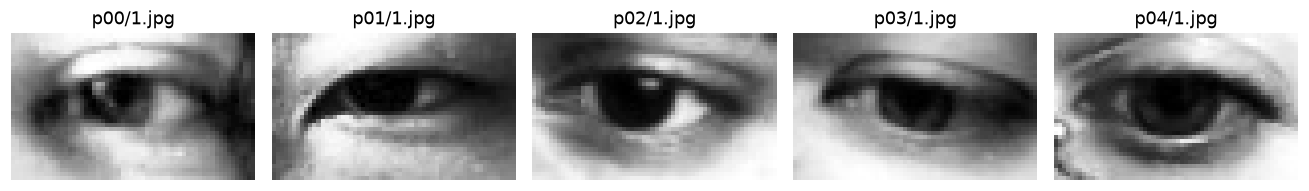

In [3]:
def load_data(data_root, persons):
    image_root, label_root = data_root / "Image", data_root / "Label"
    n = len(persons) * 3000
    # 메모리는 uint8로 보관하고, 모델에 넣을 때 float32 0~1로 바꿉니다.
    images = np.empty((n, 1, 36, 60), dtype=np.uint8)
    heads = np.empty((n, 2), dtype=np.float32)
    gazes = np.empty((n, 2), dtype=np.float32)
    owners, names = [], []
    digest = hashlib.sha256()
    offset = 0
    for person in persons:
        label_path = label_root / f"{person}.label"
        digest.update(person.encode())
        digest.update(label_path.read_bytes())
        rows = reader.read_label(label_path, header=True)
        if len(rows) != 3000:
            raise ValueError(f"{person}: 3,000개가 필요하지만 {len(rows):,}개입니다.")
        for name, gaze_text, head_text in rows:
            rel = Path(name)
            if rel.is_absolute() or ".." in rel.parts or rel.parts[0] != person:
                raise ValueError(f"잘못된 이미지 경로: {name}")
            path = image_root / rel
            raw = path.read_bytes()
            digest.update(name.encode())
            digest.update(raw)
            eye = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_GRAYSCALE)
            if eye is None or eye.shape != (36, 60):
                raise ValueError(f"36×60 이미지가 아닙니다: {path}")
            gaze = np.array(gaze_text.split(","), dtype=np.float32)
            head = np.array(head_text.split(","), dtype=np.float32)
            if gaze.shape != (2,) or head.shape != (2,):
                raise ValueError(f"각도 라벨 형태 오류: {name}")
            if not np.isfinite(gaze).all() or not np.isfinite(head).all():
                raise ValueError(f"각도에 NaN/Inf가 있습니다: {name}")
            images[offset, 0], heads[offset], gazes[offset] = eye, head, gaze
            names.append(name)
            owners.append(person)
            offset += 1
    if len(set(names)) != n:
        raise ValueError("이미지 이름이 중복되어 있습니다.")
    return {"images":images, "heads":heads, "gazes":gazes,
            "persons":np.asarray(owners), "names":np.asarray(names),
            "fingerprint":digest.hexdigest()}

DATA = load_data(DATA_ROOT, PERSONS)
counts = pd.Series(DATA["persons"]).value_counts().sort_index()
display(counts.rename_axis("person").reset_index(name="samples"))
print("총 샘플:", len(DATA["images"]), "| 입력: (1,36,60) + (2,) | 출력: (2,)")

fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
for ax, i in zip(axes, [k * 3000 for k in range(5)]):
    ax.imshow(DATA["images"][i, 0], cmap="gray", vmin=0, vmax=255)
    ax.set_title(DATA["names"][i])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 4. 데이터를 사람 단위로 나누고 평가 기준을 정하는 셀
과적합 진단은 **13명 학습 / 1명 검증 / 1명 미사용**으로 진행합니다.
진단용 학습 곡선은 학습 사람별 100개씩 고정한 1,300개 표본, 검증 곡선은 3,000개 전체를 사용합니다.

최종 LOPO에서는 **14명 42,000개 학습 / 1명 3,000개 테스트**를 지킵니다.
표준화 통계는 각 모델이 실제로 학습하는 사람들로만 계산합니다.


In [4]:
def gaze_to_3d(angles):
    angles = np.asarray(angles, dtype=np.float64)
    yaw, pitch = angles[..., 0], angles[..., 1]
    return np.stack((-np.cos(pitch) * np.sin(yaw),
                     -np.sin(pitch),
                     -np.cos(pitch) * np.cos(yaw)), axis=-1)

def angular_error(pred, target):
    a, b = gaze_to_3d(pred), gaze_to_3d(target)
    cosine = np.sum(a * b, axis=-1) / (
        np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1))
    return np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))

def split_indices(data, test_person):
    train_idx = np.flatnonzero(data["persons"] != test_person)
    test_idx = np.flatnonzero(data["persons"] == test_person)
    assert len(train_idx) == 42000 and len(test_idx) == 3000
    assert set(data["persons"][train_idx]) == set(PERSONS) - {test_person}
    assert not np.intersect1d(train_idx, test_idx).size
    return train_idx, test_idx

def fit_stats(data, train_idx):
    head = data["heads"][train_idx]
    return {
        "head_mean":head.mean(axis=0, dtype=np.float64).astype(np.float32),
        "head_std":np.maximum(head.std(axis=0, dtype=np.float64), 1e-6).astype(np.float32),
        "gaze_mean":data["gazes"][train_idx].mean(axis=0, dtype=np.float64).astype(np.float32),
    }

def batches(indices, batch_size, rng=None):
    order = rng.permutation(indices) if rng is not None else indices
    for start in range(0, len(order), batch_size):
        yield order[start:start + batch_size]

def prepare_batch(data, indices, stats, rng=None):
    eye = data["images"][indices].astype(np.float32) / np.float32(255.0)
    if rng is not None:
        shape = (len(eye), 1, 1, 1)
        contrast = rng.uniform(0.8, 1.2, size=shape).astype(np.float32)
        brightness = rng.uniform(-0.08, 0.08, size=shape).astype(np.float32)
        eye = np.clip((eye - 0.5) * contrast + 0.5 + brightness, 0, 1)
    head = (data["heads"][indices] - stats["head_mean"]) / stats["head_std"]
    target = data["gazes"][indices] - stats["gaze_mean"]
    return eye, head, target

# loss는 라디안 제곱의 평균이며, 최종 성능 지표는 각도 오차입니다.
def mse_loss(pred, target):
    diff = pred - target
    return float(np.mean(diff * diff)), diff * (2.0 / diff.size)

def diagnostic_split(data, test_person, val_person):
    if test_person == val_person or not {test_person, val_person}.issubset(PERSONS):
        raise ValueError("진단용 테스트 사람과 검증 사람은 서로 달라야 합니다.")
    train_people = [p for p in PERSONS if p not in (test_person, val_person)]
    train_idx = np.flatnonzero(np.isin(data["persons"], train_people))
    val_idx = np.flatnonzero(data["persons"] == val_person)
    assert len(train_idx) == 39000 and len(val_idx) == 3000
    assert not np.intersect1d(train_idx, val_idx).size
    return train_idx, val_idx, train_people

def fixed_train_monitor(data, train_idx, per_person, seed):
    rng = np.random.default_rng(seed)
    parts = []
    for person in np.unique(data["persons"][train_idx]):
        available = train_idx[data["persons"][train_idx] == person]
        parts.append(rng.choice(available, size=min(per_person, len(available)), replace=False))
    return np.sort(np.concatenate(parts))


## 5. CNN의 기본 부품을 NumPy로 만드는 셀
합성곱, ReLU, 풀링, 완전연결층, Dropout을 만듭니다.
모든 가중치는 **He 초기화**, 편향은 0으로 시작합니다.
Dropout은 학습 때만 켜지고, 그래프용 평가와 테스트 때는 꺼집니다.


In [5]:
class Conv2D:
    def __init__(self, in_channels, out_channels, kernel, rng, dtype=np.float32, stride=1):
        self.kernel = kernel
        self.stride = stride
        shape = (out_channels, in_channels, kernel, kernel)
        self.W = (rng.standard_normal(shape) * np.sqrt(2.0 / (in_channels * kernel**2))).astype(dtype)
        self.b = np.zeros(out_channels, dtype=dtype)

    def forward(self, x):
        self.input_shape = x.shape
        n, c, h, w = x.shape
        k = self.kernel
        oh, ow = (h - k) // self.stride + 1, (w - k) // self.stride + 1
        # 직사각형 눈 이미지의 높이와 너비를 따로 처리합니다.
        windows = np.lib.stride_tricks.sliding_window_view(x, (k, k), axis=(2, 3))
        windows = windows[:, :, ::self.stride, ::self.stride]
        self.col = windows.transpose(0, 2, 3, 1, 4, 5).reshape(n * oh * ow, c * k * k)
        out = self.col @ self.W.reshape(len(self.W), -1).T + self.b
        return out.reshape(n, oh, ow, len(self.W)).transpose(0, 3, 1, 2)

    def backward(self, dout, need_input=True):
        n, c, h, w = self.input_shape
        k, oh, ow = self.kernel, dout.shape[2], dout.shape[3]
        flat = dout.transpose(0, 2, 3, 1).reshape(-1, len(self.W))
        self.dW = (flat.T @ self.col).reshape(self.W.shape)
        self.db = flat.sum(axis=0)
        if not need_input:
            return None  # 원본 이미지의 기울기는 가중치 학습에 필요하지 않습니다.
        dcol = flat @ self.W.reshape(len(self.W), -1)
        patches = dcol.reshape(n, oh, ow, c, k, k).transpose(0, 3, 4, 5, 1, 2)
        dx = np.zeros(self.input_shape, dtype=dout.dtype)
        # 겹치는 위치의 기울기는 합산합니다.
        for ky in range(k):
            for kx in range(k):
                dx[:, :, ky:ky + oh*self.stride:self.stride, kx:kx + ow*self.stride:self.stride] += patches[:, :, ky, kx]
        return dx

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return np.maximum(x, 0)

    def backward(self, dout):
        return dout * self.mask

class MaxPool2D:
    def forward(self, x):
        self.input_shape = x.shape
        n, c, h, w = x.shape
        if h % 2 or w % 2:
            raise ValueError("2×2 풀링 입력의 높이와 너비는 짝수여야 합니다.")
        blocks = x.reshape(n, c, h//2, 2, w//2, 2).transpose(0, 1, 2, 4, 3, 5)
        blocks = blocks.reshape(n, c, h//2, w//2, 4)
        self.argmax = blocks.argmax(axis=-1)
        return blocks.max(axis=-1)

    def backward(self, dout):
        n, c, h, w = self.input_shape
        blocks = np.zeros((*dout.shape, 4), dtype=dout.dtype)
        np.put_along_axis(blocks, self.argmax[..., None], dout[..., None], axis=-1)
        return blocks.reshape(n, c, h//2, w//2, 2, 2).transpose(0, 1, 2, 4, 3, 5).reshape(self.input_shape)

class Dense:
    def __init__(self, input_size, output_size, rng, dtype=np.float32):
        scale = np.sqrt(2.0 / input_size)  # He 초기화: 모든 가중치에 적용
        self.W = (rng.standard_normal((input_size, output_size)) * scale).astype(dtype)
        self.b = np.zeros(output_size, dtype=dtype)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(axis=0)
        return dout @ self.W.T

class Dropout:
    def __init__(self, probability):
        self.p = probability

    def forward(self, x, training, rng):
        self.mask = None
        if training and self.p > 0:
            self.mask = (rng.random(x.shape) >= self.p).astype(x.dtype) / (1.0 - self.p)
            return x * self.mask
        return x

    def backward(self, dout):
        return dout if self.mask is None else dout * self.mask


## 6. 연산량을 줄인 CNN 모델을 만드는 셀
기존 모델보다 합성곱을 적은 위치에서 계산하고, 연결층도 작게 만듭니다.
속도와 성능 사이의 선택이므로 정확한 성능은 최종 평가로 확인합니다.

```
눈 이미지 (1×36×60)
 → 5×5 합성곱 12개, stride 2 + ReLU → 풀링 (12×8×14)
 → 3×3 합성곱 24개 + ReLU → 풀링 (24×3×6)
 → 완전연결 96 + ReLU + Dropout 25%
 → head pose 2개와 결합
 → 완전연결 48 + ReLU + Dropout 10%
 → 시선 각도 2개 (출력층은 선형)
```


In [6]:
class GazeCNN:
    def __init__(self, cfg, seed, dtype=np.float32):
        self.rng = np.random.default_rng(seed)
        c1, c2 = cfg["channels"]
        self.conv1 = Conv2D(1, c1, 5, self.rng, dtype, stride=2)
        self.relu1, self.pool1 = ReLU(), MaxPool2D()
        self.conv2 = Conv2D(c1, c2, 3, self.rng, dtype)
        self.relu2, self.pool2 = ReLU(), MaxPool2D()
        self.image_fc = Dense(c2 * 3 * 6, cfg["image_hidden"], self.rng, dtype)
        self.image_relu = ReLU()
        self.dropout = Dropout(cfg["dropout"])
        self.fusion_fc = Dense(cfg["image_hidden"] + 2, cfg["fusion_hidden"], self.rng, dtype)
        self.fusion_relu = ReLU()
        self.fusion_dropout = Dropout(cfg["fusion_dropout"])
        self.output_fc = Dense(cfg["fusion_hidden"], 2, self.rng, dtype)
        self.learnable = {
            "conv1":self.conv1, "conv2":self.conv2, "image_fc":self.image_fc,
            "fusion_fc":self.fusion_fc, "output_fc":self.output_fc,
        }
    
    def forward(self, eye, head_pose, training=False):
        if eye.shape[1:] != (1, 36, 60) or head_pose.shape != (len(eye), 2):
            raise ValueError("입력 형태는 (N,1,36,60), (N,2)여야 합니다.")
        # 모델 외부 입력은 0~1, 내부에서는 고정식으로 -1~1로 바꿉니다.
        x = self.pool1.forward(self.relu1.forward(self.conv1.forward(eye * 2.0 - 1.0)))
        x = self.pool2.forward(self.relu2.forward(self.conv2.forward(x)))
        self.feature_shape = x.shape
        x = self.image_relu.forward(self.image_fc.forward(x.reshape(len(x), -1)))
        x = self.dropout.forward(x, training, self.rng)
        x = np.concatenate((x, head_pose), axis=1)
        x = self.fusion_relu.forward(self.fusion_fc.forward(x))
        x = self.fusion_dropout.forward(x, training, self.rng)
        return self.output_fc.forward(x)

    def backward(self, dout, need_input_gradient=False):
        dx = self.fusion_dropout.backward(self.output_fc.backward(dout))
        dx = self.fusion_fc.backward(self.fusion_relu.backward(dx))
        dhead = dx[:, -2:]
        dx = self.dropout.backward(dx[:, :-2])
        dx = self.image_fc.backward(self.image_relu.backward(dx))
        dx = self.pool2.backward(dx.reshape(self.feature_shape))
        dx = self.conv2.backward(self.relu2.backward(dx))
        dx = self.pool1.backward(dx)
        dx = self.conv1.backward(self.relu1.backward(dx), need_input=need_input_gradient)
        return (dx * 2.0 if dx is not None else None), dhead

    def parameters(self):
        return {f"{name}.{key}":getattr(layer, key)
                for name, layer in self.learnable.items() for key in ("W", "b")}

    def gradients(self):
        return {f"{name}.{key}":getattr(layer, "d" + key)
                for name, layer in self.learnable.items() for key in ("W", "b")}

    def load_parameters(self, values):
        params = self.parameters()
        if set(values) != set(params):
            raise ValueError("저장된 가중치 이름이 모델과 다릅니다.")
        for name, param in params.items():
            if values[name].shape != param.shape:
                raise ValueError(f"가중치 형태가 다릅니다: {name}")
            param[...] = values[name]

demo_model = GazeCNN(CFG, CFG["seed"])
print(f"학습 파라미터: {sum(p.size for p in demo_model.parameters().values()):,}개")
del demo_model


학습 파라미터: 49,346개


## 7. Adam으로 가중치를 갱신하는 셀
**Adam**이 각 가중치의 수정 크기를 조절합니다.
학습률은 후반으로 갈수록 줄어듭니다. 매 모델마다 Adam 상태도 새로 초기화합니다.


In [7]:
class Adam:
    def __init__(self, params):
        self.params = params
        self.m = {key:np.zeros_like(value) for key, value in params.items()}
        self.v = {key:np.zeros_like(value) for key, value in params.items()}
        self.t = 0

    def step(self, grads, lr):
        self.t += 1
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        for key, param in self.params.items():
            grad = grads[key]
            self.m[key] *= beta1
            self.m[key] += (1 - beta1) * grad
            self.v[key] *= beta2
            self.v[key] += (1 - beta2) * grad * grad
            mhat = self.m[key] / (1 - beta1**self.t)
            vhat = self.v[key] / (1 - beta2**self.t)
            param -= lr * mhat / (np.sqrt(vhat) + eps)

def clip_gradients(grads, max_norm):
    squared = sum(float(np.sum(g * g, dtype=np.float64)) for g in grads.values())
    norm = np.sqrt(squared)
    if not np.isfinite(norm):
        raise FloatingPointError("기울기에 NaN/Inf가 발생했습니다.")
    scale = min(1.0, max_norm / (norm + 1e-12))
    for grad in grads.values():
        grad *= scale
    return norm

def learning_rate(epoch, cfg):
    warmup = cfg["warmup_epochs"]
    if epoch < warmup:
        return cfg["learning_rate"] * (epoch + 1) / warmup
    progress = (epoch - warmup) / max(1, cfg["epochs"] - warmup - 1)
    return cfg["min_learning_rate"] + 0.5 * (
        cfg["learning_rate"] - cfg["min_learning_rate"]) * (1 + np.cos(np.pi * progress))


## 8. 학습·평가·저장 기능을 준비하는 셀
가중치 갱신에는 학습 데이터만 사용합니다. 그래프용 평가는 **Dropout과 증강을 모두 끈 동일 조건**으로 계산합니다.
고정된 10 epoch 후 마지막 가중치를 사용하며, 검증·테스트 결과로 epoch나 모델을 자동 선택하지 않습니다.

새 결과는 `outputs/gaze_numpy_train2/`에 저장합니다.
이 셀은 기능만 준비하고, 아래 실행 셀에서 학습을 시작합니다.


In [8]:
def atomic_json(path, value):
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)

def atomic_csv(path, frame):
    temp = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temp, index=False)
    temp.replace(path)

def file_hash(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda:handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def make_run_signature(data, cfg):
    notebook = json.loads((PROJECT_ROOT / "train2.ipynb").read_text(encoding="utf-8"))
    sources = []
    # 실행/재개 스위치와 평가할 fold 목록은 학습 방식 자체를 바꾸지 않습니다.
    switches = {"RUN_DIAGNOSTIC", "RUN_LOPO", "RUN_SPEED_CHECK", "RESUME_COMPLETED", "FOLDS"}
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        tree = ast.parse("".join(cell["source"]))
        tree.body = [node for node in tree.body if not (
            isinstance(node, ast.Assign) and len(node.targets) == 1
            and isinstance(node.targets[0], ast.Name) and node.targets[0].id in switches)]
        sources.append(ast.dump(tree, include_attributes=False))
    payload = {"code":sources, "config":cfg, "data":data["fingerprint"],
               "diagnostic":[DIAG_TEST_PERSON, DIAG_VAL_PERSON, TRAIN_MONITOR_PER_PERSON],
               "blas":BLAS_CONFIG, "numpy":np.__version__, "opencv":cv2.__version__, "python":sys.version}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

def save_model(path, model, stats, metadata):
    arrays = {f"param::{key}":value for key, value in model.parameters().items()}
    arrays.update({f"stat::{key}":value for key, value in stats.items()})
    arrays["metadata"] = np.asarray(json.dumps(metadata, ensure_ascii=False))
    temp = path.with_suffix(".npz.tmp")
    with temp.open("wb") as handle:
        np.savez_compressed(handle, **arrays)
    temp.replace(path)

def load_model(path):
    with np.load(path, allow_pickle=False) as saved:
        meta = json.loads(str(saved["metadata"].item()))
        model = GazeCNN(meta["config"], meta["seed"])
        model.load_parameters({key.removeprefix("param::"):saved[key]
                               for key in saved.files if key.startswith("param::")})
        stats = {key.removeprefix("stat::"):saved[key].copy()
                 for key in saved.files if key.startswith("stat::")}
    return model, stats, meta

def predict(model, data, indices, stats, batch_size):
    predictions = []
    for idx in batches(indices, batch_size):
        eye = data["images"][idx].astype(np.float32) / np.float32(255.0)
        head = (data["heads"][idx] - stats["head_mean"]) / stats["head_std"]
        predictions.append(model.forward(eye, head, training=False) + stats["gaze_mean"])
    pred = np.concatenate(predictions, axis=0)
    if pred.shape != (len(indices), 2) or not np.isfinite(pred).all():
        raise FloatingPointError("예측값에 오류가 있습니다.")
    return pred

def evaluate_model(model, data, indices, stats, batch_size):
    pred = predict(model, data, indices, stats, batch_size)
    target = data["gazes"][indices]
    errors = angular_error(pred, target)
    metrics = {
        "mse_rad2":float(np.mean((pred.astype(np.float64) - target)**2)),
        "error_deg":float(errors.mean()),
        "median_error_deg":float(np.median(errors)),
    }
    return metrics, pred, errors

def plot_diagnostic(history):
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, metric, label in zip(axes, ("mse_rad2", "error_deg"),
                                ("MSE (radians squared)", "Angular error (degrees)")):
        ax.plot(frame["epoch"], frame[f"train_monitor_{metric}"], "o-", label="Train: fixed subset")
        ax.plot(frame["epoch"], frame[f"val_{metric}"], "o-", label="Validation: held-out person")
        ax.set(xlabel="Epoch", ylabel=label, title="Diagnostic model (evaluation mode)")
        ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

def fit_model(data, train_idx, cfg, folder, monitor_idx=None, val_idx=None, live=False):
    if (monitor_idx is None) != (val_idx is None):
        raise ValueError("진단에는 학습 표본과 검증 데이터가 모두 필요합니다.")
    if val_idx is not None:
        assert not np.intersect1d(train_idx, val_idx).size
        assert np.isin(monitor_idx, train_idx).all()
        assert not (set(data["persons"][train_idx]) & set(data["persons"][val_idx]))
    stats = fit_stats(data, train_idx)
    model = GazeCNN(cfg, cfg["seed"])
    optimizer = Adam(model.parameters())
    rng = np.random.default_rng(cfg["seed"])
    history, display_handle = [], None
    folder.mkdir(parents=True, exist_ok=True)

    for epoch in range(cfg["epochs"]):
        started = time.perf_counter()
        lr = learning_rate(epoch, cfg)
        total_loss, seen = 0.0, 0
        for idx in batches(train_idx, cfg["batch_size"], rng):
            aug_rng = rng if cfg["photometric_augmentation"] else None
            eye, head, target = prepare_batch(data, idx, stats, aug_rng)
            pred = model.forward(eye, head, training=True)
            loss, dout = mse_loss(pred, target)
            if not np.isfinite(loss):
                raise FloatingPointError("학습 오차에 NaN/Inf가 발생했습니다.")
            model.backward(dout)
            grads = model.gradients()
            clip_gradients(grads, cfg["gradient_clip"])
            optimizer.step(grads, lr)
            total_loss += loss * len(idx)
            seen += len(idx)
        assert seen == len(train_idx)
        row = {"epoch":epoch + 1, "train_batch_mse_rad2":total_loss / seen,
               "learning_rate":lr}
        # 진단 곡선은 매 epoch 종료 시점의 같은 모델로 비교합니다.
        if val_idx is not None:
            train_metrics, _, _ = evaluate_model(model, data, monitor_idx, stats, cfg["batch_size"])
            val_metrics, _, _ = evaluate_model(model, data, val_idx, stats, cfg["batch_size"])
            for key in ("mse_rad2", "error_deg"):
                row[f"train_monitor_{key}"] = train_metrics[key]
                row[f"val_{key}"] = val_metrics[key]
            row["val_minus_train_deg"] = val_metrics["error_deg"] - train_metrics["error_deg"]
        row["seconds"] = time.perf_counter() - started
        history.append(row)
        atomic_csv(folder / "history.csv", pd.DataFrame(history))
        status = (f"{folder.name} | {epoch + 1:02d}/{cfg['epochs']} | "
                  f"batch MSE {row['train_batch_mse_rad2']:.5f} | {row['seconds']:.1f}s")
        if val_idx is not None:
            status += (f" | train {row['train_monitor_error_deg']:.2f}°"
                       f" | validation {row['val_error_deg']:.2f}°")
        print(status, flush=True)
        if live and val_idx is not None:
            fig = plot_diagnostic(history)
            if display_handle is None:
                display_handle = display(fig, display_id=True)
            else:
                display_handle.update(fig)
            plt.close(fig)
    return model, stats, pd.DataFrame(history)

def valid_completed(folder, signature, kind, epochs):
    marker = folder / "result.json"
    if not marker.is_file():
        return None
    try:
        record = json.loads(marker.read_text(encoding="utf-8"))
        if (record["signature"] != signature or record["kind"] != kind
                or record["epochs"] != epochs):
            return None
        needed = {"model.npz", "history.csv"}
        needed |= {"predictions.csv"} if kind == "lopo" else {"diagnostic_curves.png"}
        if set(record["files"]) != needed:
            return None
        for name in needed:
            if file_hash(folder / name) != record["files"][name]:
                return None
        if len(pd.read_csv(folder / "history.csv")) != epochs:
            return None
        return record
    except (OSError, ValueError, KeyError, TypeError):
        return None


## 9. 현재 맥에서 학습 속도를 가볍게 측정하는 셀
가상 이미지 몇 배치로 처리 시간을 재고, 한 fold의 학습 계산 시간을 대략 표시합니다.
실제 데이터 학습이나 성능 평가는 하지 않습니다. 임시 모델은 버립니다.


In [9]:
def benchmark_speed(cfg):
    rng = np.random.default_rng(123)
    n = cfg["batch_size"]
    eye = rng.random((n, 1, 36, 60), dtype=np.float32)
    head = rng.standard_normal((n, 2)).astype(np.float32)
    target = rng.normal(0, 0.2, (n, 2)).astype(np.float32)
    model = GazeCNN(cfg, cfg["seed"])
    optimizer = Adam(model.parameters())
    elapsed = []
    for step in range(4):  # 첫 회는 준비 시간으로 제외합니다.
        start = time.perf_counter()
        _, dout = mse_loss(model.forward(eye, head, training=True), target)
        model.backward(dout)
        grads = model.gradients()
        clip_gradients(grads, cfg["gradient_clip"])
        optimizer.step(grads, cfg["learning_rate"])
        elapsed.append(time.perf_counter() - start)
    seconds = float(np.median(elapsed[1:]))
    estimate = seconds * int(np.ceil(42000 / n)) * cfg["epochs"] / 60
    display(pd.DataFrame([{
        "batch_size":n, "seconds_per_step":seconds,
        "training_only_minutes_per_fold":estimate,
        "parameters":sum(p.size for p in model.parameters().values()),
    }]).round(4))
    print("시간은 짧은 측정에 따른 추정이며 평가·파일 저장·발열에 따른 변화는 포함하지 않습니다.")
    return seconds

STEP_SECONDS = benchmark_speed(CFG) if RUN_SPEED_CHECK else None


,batch_size,seconds_per_step,training_only_minutes_per_fold,parameters
0,128,0.0144,0.7907,49346


시간은 짧은 측정에 따른 추정이며 평가·파일 저장·발열에 따른 변화는 포함하지 않습니다.


## 10. 과적합을 확인하는 학습·검증 그래프를 만드는 셀 — 진단 학습 시작
p00은 사용하지 않고, p01을 검증용으로 남깁니다. 나머지 13명으로 별도 모델을 10 epoch 학습합니다.
학습 곡선은 고정한 1,300개 표본, 검증 곡선은 3,000개 전체로 계산하며 매 epoch 갱신합니다.

**학습 오차는 내려가는데 검증 오차가 여러 epoch 동안 올라가면 과적합의 징후**입니다.
두 곡선에 차이가 있다는 사실만으로 과적합을 확정하지는 않습니다.
이 진단 모델은 최종 LOPO 모델로 재사용하지 않습니다.


결과 저장: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation/outputs/gaze_numpy_train2/3acce9b179203da6
diagnostic | 01/10 | batch MSE 0.02067 | 4.1s | train 7.15° | validation 8.11°


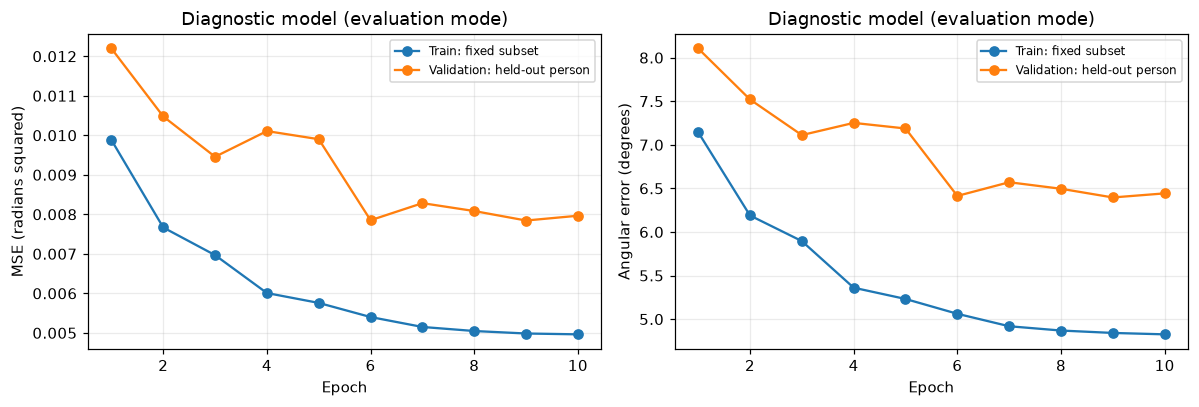

diagnostic | 02/10 | batch MSE 0.01019 | 4.1s | train 6.19° | validation 7.52°
diagnostic | 03/10 | batch MSE 0.00866 | 4.2s | train 5.90° | validation 7.11°
diagnostic | 04/10 | batch MSE 0.00780 | 4.1s | train 5.36° | validation 7.25°
diagnostic | 05/10 | batch MSE 0.00723 | 4.1s | train 5.23° | validation 7.19°
diagnostic | 06/10 | batch MSE 0.00687 | 4.4s | train 5.06° | validation 6.41°
diagnostic | 07/10 | batch MSE 0.00659 | 4.1s | train 4.92° | validation 6.57°
diagnostic | 08/10 | batch MSE 0.00639 | 4.1s | train 4.87° | validation 6.50°
diagnostic | 09/10 | batch MSE 0.00626 | 4.2s | train 4.84° | validation 6.40°
diagnostic | 10/10 | batch MSE 0.00620 | 4.1s | train 4.83° | validation 6.44°


,epoch,train_monitor_mse_rad2,val_mse_rad2,train_monitor_error_deg,val_error_deg,val_minus_train_deg
0,1,0.0099,0.0122,7.1452,8.1056,0.9604
1,2,0.0077,0.0105,6.1894,7.5205,1.3311
2,3,0.0070,0.0095,5.8955,7.1118,1.2162
3,4,0.0060,0.0101,5.3608,7.2515,1.8908
4,5,0.0058,0.0099,5.2315,7.1874,1.9560
5,6,0.0054,0.0079,5.0614,6.4136,1.3522
6,7,0.0052,0.0083,4.9185,6.5707,1.6522
7,8,0.0050,0.0081,4.8692,6.4958,1.6266
8,9,0.0050,0.0078,4.8416,6.3961,1.5544
9,10,0.0050,0.0080,4.8256,6.4429,1.6173


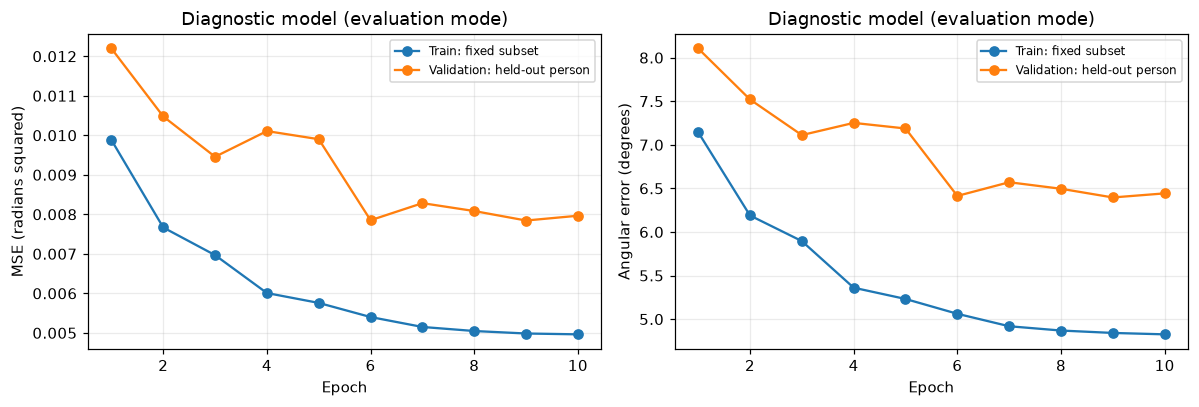

train: 고정 학습 표본 / validation: 학습에 쓰지 않은 사람 전체
검증 곡선의 지속적인 상승 여부를 확인하세요. 이 코드에는 자동 모델 선택이 없습니다.


In [10]:
RUN_SIGNATURE = make_run_signature(DATA, CFG)
RUN_DIR = OUTPUT_BASE / RUN_SIGNATURE[:16]
RUN_DIR.mkdir(parents=True, exist_ok=True)
atomic_json(RUN_DIR / "config.json", {
    "signature":RUN_SIGNATURE, "config":CFG, "data_root":str(DATA_ROOT),
    "diagnostic_test_person":DIAG_TEST_PERSON, "diagnostic_val_person":DIAG_VAL_PERSON,
    "train_monitor_per_person":TRAIN_MONITOR_PER_PERSON,
    "data_fingerprint":DATA["fingerprint"],
})
print("결과 저장:", RUN_DIR)

def run_diagnostic(data, cfg, run_dir, signature, resume=True):
    folder = run_dir / "diagnostic"
    record = valid_completed(folder, signature, "diagnostic", cfg["epochs"]) if resume else None
    train_idx, val_idx, train_people = diagnostic_split(data, DIAG_TEST_PERSON, DIAG_VAL_PERSON)
    monitor_idx = fixed_train_monitor(data, train_idx, TRAIN_MONITOR_PER_PERSON, cfg["seed"])
    if record is None:
        folder.mkdir(parents=True, exist_ok=True)
        (folder / "result.json").unlink(missing_ok=True)
        model, stats, history = fit_model(
            data, train_idx, cfg, folder, monitor_idx, val_idx, live=True)
        meta = {"signature":signature, "config":cfg, "seed":cfg["seed"],
                "train_people":train_people, "test_person":DIAG_TEST_PERSON,
                "val_person":DIAG_VAL_PERSON, "epochs":cfg["epochs"], "kind":"diagnostic"}
        save_model(folder / "model.npz", model, stats, meta)
        fig = plot_diagnostic(history)
        fig.savefig(folder / "diagnostic_curves.png", bbox_inches="tight")
        plt.close(fig)
        record = {"signature":signature, "kind":"diagnostic", "epochs":cfg["epochs"],
                  "train_samples":len(train_idx), "val_samples":len(val_idx),
                  "monitor_samples":len(monitor_idx),
                  "files":{name:file_hash(folder / name) for name in
                           ("model.npz", "history.csv", "diagnostic_curves.png")}}
        atomic_json(folder / "result.json", record)
    else:
        print("완료된 진단 결과를 불러옵니다.")
        history = pd.read_csv(folder / "history.csv")
    display(history[["epoch", "train_monitor_mse_rad2", "val_mse_rad2",
                     "train_monitor_error_deg", "val_error_deg", "val_minus_train_deg"]].round(4))
    fig = plot_diagnostic(history)
    plt.show()
    print("train: 고정 학습 표본 / validation: 학습에 쓰지 않은 사람 전체")
    print("검증 곡선의 지속적인 상승 여부를 확인하세요. 이 코드에는 자동 모델 선택이 없습니다.")
    return history

DIAGNOSTIC_HISTORY = (run_diagnostic(DATA, CFG, RUN_DIR, RUN_SIGNATURE, RESUME_COMPLETED)
                      if RUN_DIAGNOSTIC else None)
if not RUN_DIAGNOSTIC:
    print("진단 학습을 건너뜁니다.")


## 11. 15-fold 최종 학습과 테스트를 실행하는 셀
매 fold마다 모델·Adam 상태·표준화 통계를 새로 만듭니다.
**14명 전체로 10 epoch 학습한 뒤**, 학습 42,000개와 테스트 3,000개의 최종 오차를 각각 계산합니다.

테스트 사람의 데이터는 학습·검증·설정 선택에 사용하지 않습니다.
아래 학습·테스트 비교는 마지막 시점의 결과이며, 테스트 곡선으로 학습 중 모델을 고르지 않습니다.


In [11]:
def train_fold(data, test_person, cfg, folder, signature):
    train_idx, test_idx = split_indices(data, test_person)
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "result.json").unlink(missing_ok=True)
    started = time.perf_counter()
    model, stats, history = fit_model(data, train_idx, cfg, folder)
    metadata = {"signature":signature, "kind":"lopo", "config":cfg, "seed":cfg["seed"],
                "test_person":test_person, "train_people":[p for p in PERSONS if p != test_person],
                "epochs":cfg["epochs"], "weights":"last epoch"}
    save_model(folder / "model.npz", model, stats, metadata)

    # 동일한 최종 모델, Dropout OFF, 증강 OFF로 train/test를 비교합니다.
    train_metrics, _, _ = evaluate_model(model, data, train_idx, stats, cfg["batch_size"])
    test_metrics, pred, errors = evaluate_model(model, data, test_idx, stats, cfg["batch_size"])
    target = data["gazes"][test_idx]
    frame = pd.DataFrame({
        "name":data["names"][test_idx],
        "gt_yaw_rad":target[:, 0], "gt_pitch_rad":target[:, 1],
        "pred_yaw_rad":pred[:, 0], "pred_pitch_rad":pred[:, 1],
        "angular_error_deg":errors,
    })
    atomic_csv(folder / "predictions.csv", frame)
    result = {
        "signature":signature, "kind":"lopo", "test_person":test_person,
        "epochs":cfg["epochs"], "train_samples":len(train_idx), "test_samples":len(test_idx),
        "train_mse_rad2":train_metrics["mse_rad2"], "test_mse_rad2":test_metrics["mse_rad2"],
        "train_error_deg":train_metrics["error_deg"], "mean_error_deg":test_metrics["error_deg"],
        "median_error_deg":test_metrics["median_error_deg"],
        "test_minus_train_deg":test_metrics["error_deg"] - train_metrics["error_deg"],
        "train_minutes":(time.perf_counter() - started) / 60,
        "files":{name:file_hash(folder / name) for name in
                 ("model.npz", "history.csv", "predictions.csv")},
    }
    atomic_json(folder / "result.json", result)
    return result

def run_lopo(data, cfg, folds, run_dir, signature, resume=True):
    if not folds or len(set(folds)) != len(folds) or not set(folds).issubset(PERSONS):
        raise ValueError("FOLDS는 p00~p14 중 중복 없는 목록이어야 합니다.")
    results = []
    for number, person in enumerate(folds, 1):
        folder = run_dir / person
        result = valid_completed(folder, signature, "lopo", cfg["epochs"]) if resume else None
        if result is not None and (result["test_person"] != person
                                   or result["train_samples"] != 42000
                                   or result["test_samples"] != 3000):
            result = None
        if result is None:
            print(f"\n[{number}/{len(folds)}] 테스트 {person}: 새 모델 학습", flush=True)
            result = train_fold(data, person, cfg, folder, signature)
        else:
            print(f"\n[{number}/{len(folds)}] {person}: 완료된 결과 불러오기")
        results.append({key:value for key, value in result.items()
                        if key not in ("signature", "files", "kind")})
        atomic_csv(run_dir / "fold_results.csv", pd.DataFrame(results))
        print(f"train {result['train_error_deg']:.3f}° / test {result['mean_error_deg']:.3f}°")
    return pd.DataFrame(results)

RESULTS = (run_lopo(DATA, CFG, FOLDS, RUN_DIR, RUN_SIGNATURE, RESUME_COMPLETED)
           if RUN_LOPO else None)
if not RUN_LOPO:
    print("최종 15-fold 평가는 건너뛰었습니다. 진단 그래프는 위 셀에서 확인하세요.")



[1/15] 테스트 p00: 새 모델 학습
p00 | 01/10 | batch MSE 0.02045 | 4.2s
p00 | 02/10 | batch MSE 0.01053 | 4.2s
p00 | 03/10 | batch MSE 0.00866 | 4.1s
p00 | 04/10 | batch MSE 0.00773 | 4.2s
p00 | 05/10 | batch MSE 0.00723 | 4.1s
p00 | 06/10 | batch MSE 0.00682 | 4.1s
p00 | 07/10 | batch MSE 0.00655 | 4.3s
p00 | 08/10 | batch MSE 0.00637 | 4.1s
p00 | 09/10 | batch MSE 0.00626 | 4.2s
p00 | 10/10 | batch MSE 0.00627 | 4.1s
train 4.926° / test 4.656°

[2/15] 테스트 p01: 새 모델 학습
p01 | 01/10 | batch MSE 0.02018 | 4.1s
p01 | 02/10 | batch MSE 0.01013 | 5.6s
p01 | 03/10 | batch MSE 0.00842 | 4.3s
p01 | 04/10 | batch MSE 0.00756 | 4.1s
p01 | 05/10 | batch MSE 0.00705 | 4.3s
p01 | 06/10 | batch MSE 0.00665 | 4.2s
p01 | 07/10 | batch MSE 0.00637 | 4.1s
p01 | 08/10 | batch MSE 0.00620 | 4.1s
p01 | 09/10 | batch MSE 0.00609 | 4.1s
p01 | 10/10 | batch MSE 0.00613 | 4.1s
train 4.866° / test 6.571°

[3/15] 테스트 p02: 새 모델 학습
p02 | 01/10 | batch MSE 0.02052 | 4.0s
p02 | 02/10 | batch MSE 0.01027 | 4.1s
p02 | 03/10 |

## 12. 학습·테스트 성능을 표와 그래프로 비교하는 셀
각 사람을 테스트한 모델의 **최종 학습 오차와 테스트 오차**를 나란히 표시합니다.
또한 15개 테스트 오차의 평균을 최종 성능으로 보고합니다. 각도 오차는 작을수록 좋습니다.

학습과 테스트 사이의 차이는 일반화 차이입니다. 과적합의 진행 여부는 위의 학습·검증 곡선과 함께 판단하세요.
별도로 표시하는 학습 배치 MSE 곡선에는 Dropout과 증강이 적용되어 있습니다.


,테스트 사람,train_samples,test_samples,train_mse_rad2,test_mse_rad2,학습 각도 오차(°),테스트 각도 오차(°),test-train 차이(°),train_minutes
0,p00,42000,3000,0.0051,0.0042,4.9260,4.6559,-0.2701,0.7366
1,p01,42000,3000,0.0050,0.0082,4.8656,6.5707,1.7051,0.7602
2,p02,42000,3000,0.0050,0.0052,4.8442,5.1816,0.3375,0.7326
3,p03,42000,3000,0.0048,0.0098,4.7822,6.5458,1.7636,0.7267
4,p04,42000,3000,0.0049,0.0071,4.8189,5.7753,0.9564,0.7229
5,p05,42000,3000,0.0048,0.0080,4.7242,6.3080,1.5839,0.7222
6,p06,42000,3000,0.0047,0.0089,4.7262,6.6939,1.9677,0.7218
7,p07,42000,3000,0.0046,0.0127,4.6547,7.8175,3.1627,0.7206
8,p08,42000,3000,0.0047,0.0094,4.7266,6.7794,2.0528,0.7210
9,p09,42000,3000,0.0048,0.0109,4.7369,7.4880,2.7511,0.7212


최종 15-fold: 평균 테스트 각도 오차 6.258°


,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14,평균
각도 오차 (°),4.656,6.571,5.182,6.546,5.775,6.308,6.694,7.817,6.779,7.488,5.772,5.538,5.996,6.641,6.103,6.258


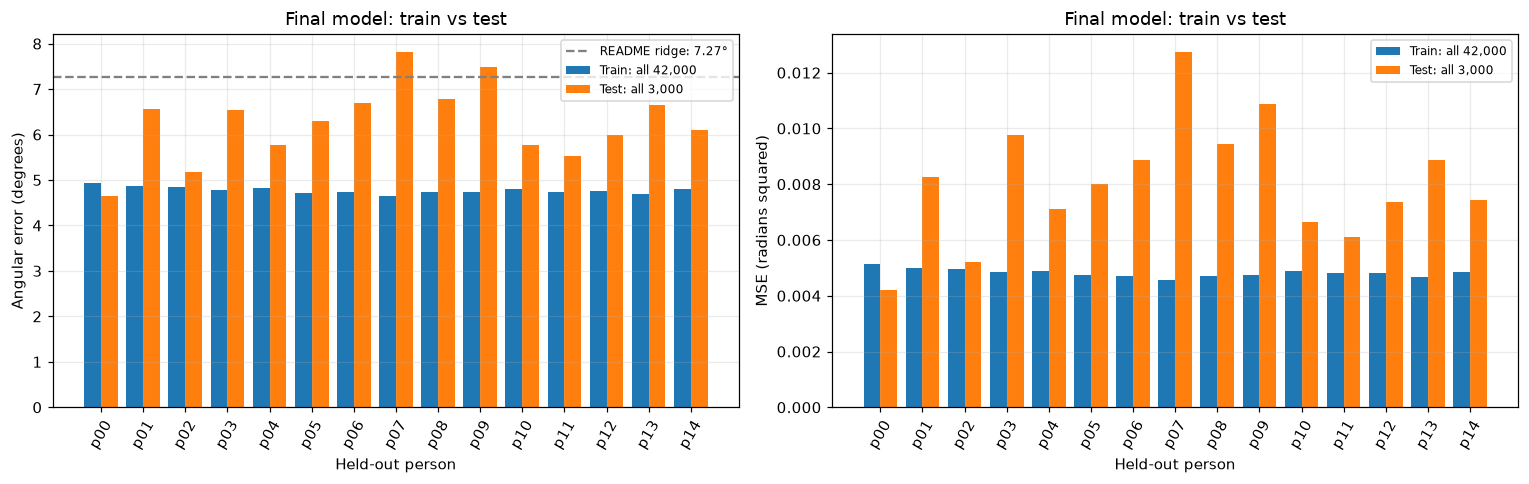

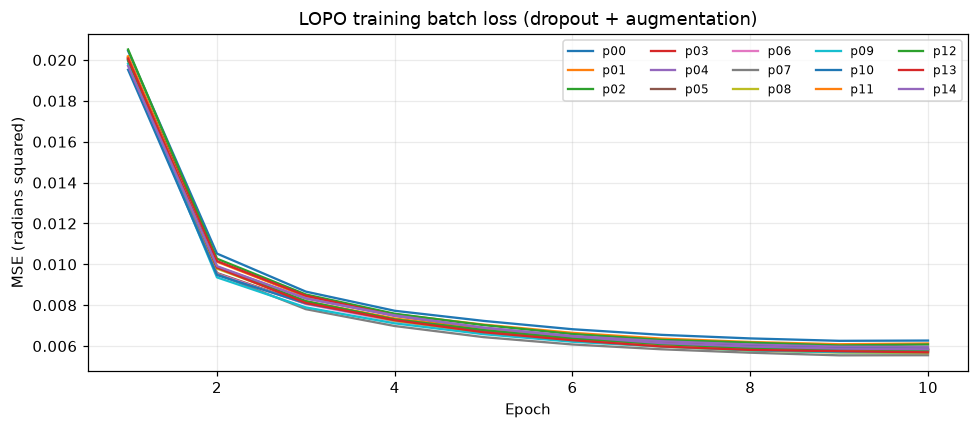

결과 저장: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation/outputs/gaze_numpy_train2/3acce9b179203da6


In [12]:
def show_report(results, run_dir):
    report = results.sort_values("test_person").reset_index(drop=True)
    complete = len(report) == 15 and set(report["test_person"]) == set(PERSONS)
    mean_error = float(report["mean_error_deg"].mean())
    columns = ["test_person", "train_samples", "test_samples", "train_mse_rad2",
               "test_mse_rad2", "train_error_deg", "mean_error_deg",
               "test_minus_train_deg", "train_minutes"]
    display(report[columns].rename(columns={
        "test_person":"테스트 사람", "train_error_deg":"학습 각도 오차(°)",
        "mean_error_deg":"테스트 각도 오차(°)", "test_minus_train_deg":"test-train 차이(°)",
    }).round(4))
    prefix = "최종 15-fold" if complete else f"부분 결과 {len(report)}/15 fold"
    print(f"{prefix}: 평균 테스트 각도 오차 {mean_error:.3f}°")
    if not complete:
        print("15명 전체를 평가하기 전에는 최종 성능으로 보고하지 마세요.")
    wide = pd.DataFrame([{
        **dict(zip(report["test_person"], report["mean_error_deg"])),
        ("평균" if complete else "부분 평균"):mean_error,
    }], index=["각도 오차 (°)"])
    display(wide.round(3))
    atomic_csv(run_dir / "report_lopo.csv", wide.rename_axis("metric").reset_index())
    atomic_json(run_dir / "summary.json", {
        "complete_15_folds":complete, "folds":report["test_person"].tolist(),
        "mean_test_error_deg":mean_error,
        "mean_train_error_deg":float(report["train_error_deg"].mean()),
        "fold_std_deg":float(report["mean_error_deg"].std(ddof=0)),
        "epochs_per_model":CFG["epochs"],
    })

    x = np.arange(len(report))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, train_key, test_key, ylabel in zip(
            axes, ("train_error_deg", "train_mse_rad2"),
            ("mean_error_deg", "test_mse_rad2"),
            ("Angular error (degrees)", "MSE (radians squared)")):
        ax.bar(x - 0.2, report[train_key], width=0.4, label="Train: all 42,000")
        ax.bar(x + 0.2, report[test_key], width=0.4, label="Test: all 3,000")
        ax.set_xticks(x, report["test_person"], rotation=60)
        ax.set(title="Final model: train vs test", xlabel="Held-out person", ylabel=ylabel)
        ax.legend(fontsize=8)
    axes[0].axhline(7.27, color="gray", linestyle="--", label="README ridge: 7.27°")
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(run_dir / "train_test_comparison.png", bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4))
    for person in report["test_person"]:
        history = pd.read_csv(run_dir / person / "history.csv")
        ax.plot(history["epoch"], history["train_batch_mse_rad2"], label=person)
    ax.set(title="LOPO training batch loss (dropout + augmentation)",
           xlabel="Epoch", ylabel="MSE (radians squared)")
    ax.legend(ncol=5, fontsize=8)
    fig.tight_layout()
    fig.savefig(run_dir / "lopo_training_curves.png", bbox_inches="tight")
    plt.show()
    print("결과 저장:", run_dir)
    return report

report = show_report(RESULTS, RUN_DIR) if RESULTS is not None else None
if report is None:
    print("최종 성능 표는 RUN_LOPO=True로 평가한 뒤 표시됩니다.")


## 13. 저장한 모델의 예측을 확인하는 셀
해당 사람을 학습에서 제외한 모델로 눈 이미지의 정답과 예측을 비교합니다.
산점도의 점이 대각선에 가까울수록 예측이 정확합니다.


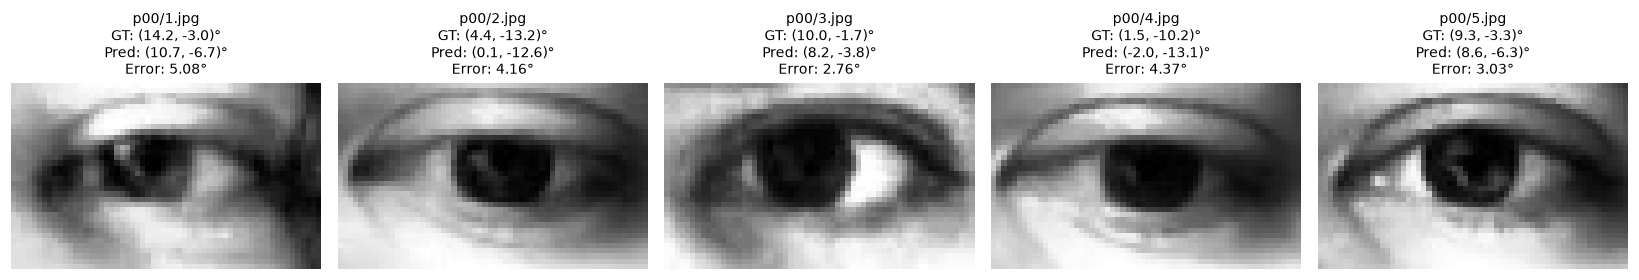

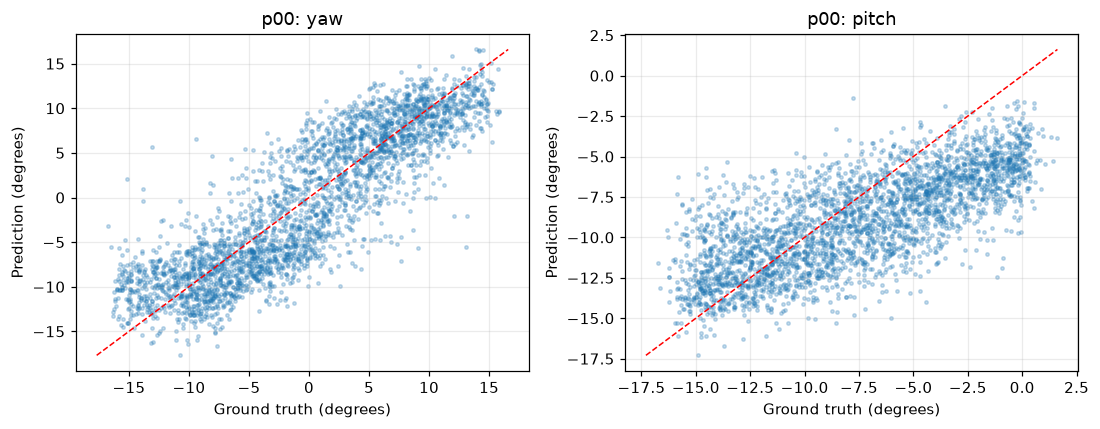

In [13]:
if report is not None:
    EXAMPLE_PERSON = report["test_person"].iloc[0]
    saved_model, saved_stats, saved_meta = load_model(RUN_DIR / EXAMPLE_PERSON / "model.npz")
    assert saved_meta["test_person"] == EXAMPLE_PERSON
    assert EXAMPLE_PERSON not in saved_meta["train_people"]
    example_idx = np.flatnonzero(DATA["persons"] == EXAMPLE_PERSON)[:5]
    example_pred = predict(saved_model, DATA, example_idx, saved_stats, CFG["batch_size"])
    example_gt = DATA["gazes"][example_idx]
    example_errors = angular_error(example_pred, example_gt)
    
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))
    for ax, idx, pred, gt, err in zip(axes, example_idx, example_pred, example_gt, example_errors):
        ax.imshow(DATA["images"][idx, 0], cmap="gray", vmin=0, vmax=255)
        pred_deg, gt_deg = np.degrees(pred), np.degrees(gt)
        ax.set_title(f"{DATA['names'][idx]}\n"
                     f"GT: ({gt_deg[0]:.1f}, {gt_deg[1]:.1f})°\n"
                     f"Pred: ({pred_deg[0]:.1f}, {pred_deg[1]:.1f})°\nError: {err:.2f}°", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(RUN_DIR / "prediction_examples.png", bbox_inches="tight")
    plt.show()
    
    predictions = pd.read_csv(RUN_DIR / EXAMPLE_PERSON / "predictions.csv")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, angle in zip(axes, ("yaw", "pitch")):
        gt = np.degrees(predictions[f"gt_{angle}_rad"].to_numpy())
        pred = np.degrees(predictions[f"pred_{angle}_rad"].to_numpy())
        limits = [min(gt.min(), pred.min()), max(gt.max(), pred.max())]
        ax.scatter(gt, pred, s=5, alpha=0.25)
        ax.plot(limits, limits, "r--", linewidth=1)
        ax.set(title=f"{EXAMPLE_PERSON}: {angle}", xlabel="Ground truth (degrees)",
               ylabel="Prediction (degrees)")
    plt.tight_layout()
    fig.savefig(RUN_DIR / "prediction_scatter.png", bbox_inches="tight")
    plt.show()
    del saved_model
else:
    print("예측 예시는 최종 LOPO 평가 후 확인할 수 있습니다.")


### 실행 순서와 결과 해석
- **빨리 진단만 보기:** 2번에서 `RUN_LOPO=False` → 10번까지 실행합니다.
- **정식 평가:** `RUN_LOPO=True`, `FOLDS=PERSONS.copy()`로 15명 전체를 평가합니다.
- 완료된 진단/모델은 같은 코드·설정·데이터에서 재사용합니다. 중단된 모델은 처음부터 다시 학습합니다.
- 진단 모델 1개 + 최종 모델 15개를 각각 10 epoch 학습합니다. 이전 모델의 가중치를 이어받지 않습니다.
- 진단 곡선만으로 모든 사람의 과적합 여부가 확정되는 것은 아닙니다. 검증 사람 1명에 대한 관찰입니다.
- 진단은 고정 설정의 상태 확인용입니다. 진단의 검증 사람도 이후 LOPO에서는 테스트 대상이 되므로, 이 곡선으로 전체 평가의 설정을 튜닝하지 않습니다. 튜닝은 각 fold의 테스트 사람을 제외한 내부 검증으로 별도 진행해야 합니다.
- 테스트 결과를 보고 학습 횟수나 설정을 바꾸면 독립적인 최종 평가가 아닙니다.
- 속도 향상을 위해 모델 크기를 줄였으므로 이전 모델보다 성능이 높다고 보장하지 않습니다.
- 설정이나 코드를 바꾼 뒤에는 커널을 재시작하고 위에서부터 실행하세요.
